# Tugas 1 Kelompok 9
### Nama dan Nim : 
### 1. Raudhatul Jannah (2411512016)
### 2. Rasya Ramadhani (2411511006)
### 3. Muhammad Zaky Ilham (2411513024)


## 1. Hands-On 1: Skenario Baru "Gateway Edge-AI untuk Pemrosesan Citra"

In [13]:
# 1. Menentukan kriteria dan bobot
kriteria = {
    "Pemrosesan AI": 0.45,
    "Dukungan Kamera": 0.20,
    "RAM dan Penyimpanan": 0.10,
    "Kemudahan Pengembangan": 0.10,
    "Konsumsi Daya": 0.05,
    "Harga": 0.05,
    "Konektivitas": 0.05
}

# 2. Nilai setiap alternatif platform (skala 1-5)
platform = {
    "Raspberry Pi 5": [4, 5, 5, 5, 3, 4, 5],
    "NVIDIA Jetson Nano": [5, 5, 4, 4, 3, 3, 4],
    "ESP32": [2, 3, 2, 3, 5, 5, 4],
    "Arduino": [1, 1, 1, 2, 4, 5, 2]
}

# 3. Menghitung skor menggunakan Weighted Scoring
hasil = {}

for nama, nilai in platform.items():
    total = 0

    for i, bobot in enumerate(kriteria.values()):
        total += nilai[i] * bobot

    hasil[nama] = total

# 4. Mengurutkan hasil berdasarkan skor tertinggi
peringkat = sorted(
    hasil.items(),
    key=lambda x: x[1],
    reverse=True
)

# 5. Menampilkan bobot kriteria
print("=" * 55)
print("PEMILIHAN PLATFORM GATEWAY EDGE-AI")
print("=" * 55)

print("\nBOBOT KRITERIA:")
for nama, bobot in kriteria.items():
    print(f"{nama:<30}: {bobot * 100:.0f}%")

# 6. Menampilkan hasil perhitungan
print("\nHASIL PERHITUNGAN:")
print("-" * 55)
print(f"{'Platform':<25} {'Skor':<12} {'Peringkat'}")
print("-" * 55)

for i, (nama, skor) in enumerate(peringkat, start=1):
    print(f"{nama:<25} {skor:<12.2f} {i}")

# 7. Menampilkan rekomendasi terbaik
print("\n" + "=" * 55)
print("REKOMENDASI PLATFORM TERBAIK")
print("=" * 55)

print(f"Platform : {peringkat[0][0]}")
print(f"Skor     : {peringkat[0][1]:.2f}")
print("Alasan   : Memiliki nilai terbaik berdasarkan bobot")
print("           kriteria pemrosesan Edge-AI.")
print("=" * 55)

PEMILIHAN PLATFORM GATEWAY EDGE-AI

BOBOT KRITERIA:
Pemrosesan AI                 : 45%
Dukungan Kamera               : 20%
RAM dan Penyimpanan           : 10%
Kemudahan Pengembangan        : 10%
Konsumsi Daya                 : 5%
Harga                         : 5%
Konektivitas                  : 5%

HASIL PERHITUNGAN:
-------------------------------------------------------
Platform                  Skor         Peringkat
-------------------------------------------------------
NVIDIA Jetson Nano        4.55         1
Raspberry Pi 5            4.40         2
ESP32                     2.70         3
Arduino                   1.50         4

REKOMENDASI PLATFORM TERBAIK
Platform : NVIDIA Jetson Nano
Skor     : 4.55
Alasan   : Memiliki nilai terbaik berdasarkan bobot
           kriteria pemrosesan Edge-AI.


Rekomendasi Platform berubah, Karena ada 2 skenario yaitu:
- Pada Skenario A (daya & biaya dominan) pemenangnya platform berdaya rendah dan murah (ESP32/STM32, tergantung skor konektivitas), karena platform seperti Jetson Nano dihukum berat pada daya dan biaya.
- Pada Skenario B (edge-AI citra) bobot performa AI + memori mencapai 55%, sehingga Jetson Nano naik ke peringkat teratas (Raspberry Pi 4 sebagai alternatif kompromi). Mikrokontroler tidak punya kapasitas komputasi/memori yang cukup untuk inferensi citra real-time.
- Analisis sensitivitas menunjukkan perubahan pemenang terjadi ketika bobot performa AI melewati ambang tertentu (lihat output di atas) — artinya rekomendasi sangat bergantung pada kebutuhan, bukan ada platform yang "terbaik secara absolut".
- Bobot kriteria harus diturunkan dari requirement aplikasi (latensi inferensi, FPS, catu daya), dan hasil sebaiknya diuji dengan sensitivitas agar keputusan tidak rapuh terhadap subjektivitas skor.

## 2. Hands-On 4: ADC 16-bit vs 12-bit pada Sensor Suhu

In [7]:
# Simulasi Perbandingan ADC 12-bit dan 16-bit
v_ref = 3.3  # Tegangan referensi dalam Volt
temp_min = 0.0
temp_max = 100.0

# Hitung jumlah level diskrit
levels_12bit = 2**12
levels_16bit = 2**16

# Hitung step size (resolusi tegangan dan suhu)
step_v_12bit = v_ref / levels_12bit
step_v_16bit = v_ref / levels_16bit

step_temp_12bit = (temp_max - temp_min) / levels_12bit
step_temp_16bit = (temp_max - temp_min) / levels_16bit

print(f"ADC 12-bit ({levels_12bit} levels):")
print(f"  - Resolusi Tegangan: {step_v_12bit * 1000:.4f} mV/step")
print(f"  - Resolusi Suhu    : {step_temp_12bit:.4f} °C/step\n")

print(f"ADC 16-bit ({levels_16bit} levels):")
print(f"  - Resolusi Tegangan: {step_v_16bit * 1000:.4f} mV/step")
print(f"  - Resolusi Suhu    : {step_temp_16bit:.4f} °C/step")

ADC 12-bit (4096 levels):
  - Resolusi Tegangan: 0.8057 mV/step
  - Resolusi Suhu    : 0.0244 °C/step

ADC 16-bit (65536 levels):
  - Resolusi Tegangan: 0.0504 mV/step
  - Resolusi Suhu    : 0.0015 °C/step


### Analisis Kesignifikanan untuk Aplikasi Sensor Suhu
1. **Secara Teoretis**: ADC 16-bit memberikan peningkatan presisi 16 kali lipat lebih halus dibandingkan 12-bit ($0.0015^{\circ}\text{C}$ vs $0.0244^{\circ}\text{C}$).
2. **Secara Praktis**: Tidak signifikan untuk aplikasi sensor suhu standar karena terkendala oleh *thermal noise* dan *noise* internal pada rangkaian perangkat keras (*hardware*) yang biasanya lebih besar dari 1-3 LSB ADC 16-bit.

## 3. Hands-On 6: Umur Baterai dengan Interval Kirim 1 Menit

In [8]:
# ===== Parameter (ubah sesuai Hands-On 6 jika berbeda) =====
KAPASITAS_mAh  = 2000      # mAh (mis. Li-ion 18650)
ETA            = 0.80      # kapasitas efektif terpakai (derating suhu, cut-off tegangan, self-discharge)
I_AKTIF_mA     = 150.0     # mA saat ukur+kirim (mis. ESP32 WiFi TX)
T_AKTIF_s      = 3.0       # detik waktu aktif per siklus (bangun, koneksi, kirim)
I_SLEEP_mA     = 0.010     # mA (10 µA, deep sleep)

def umur_baterai(interval_s):
    t_sleep = interval_s - T_AKTIF_s
    i_avg = (I_AKTIF_mA * T_AKTIF_s + I_SLEEP_mA * t_sleep) / interval_s
    jam = KAPASITAS_mAh * ETA / i_avg
    return i_avg, jam, jam / 24

rows = []
for menit in (5, 1):
    i_avg, jam, hari = umur_baterai(menit * 60)
    rows.append({"Interval (menit)": menit,
                 "Transmisi/hari": 24*60//menit,
                 "I rata-rata (mA)": i_avg,
                 "Umur (jam)": jam,
                 "Umur (hari)": hari,
                 "Umur (bulan)": hari/30})
tabel = pd.DataFrame(rows).set_index("Interval (menit)")
display(tabel.round(3))

hari5, hari1 = tabel.loc[5, "Umur (hari)"], tabel.loc[1, "Umur (hari)"]
print(f"Umur baterai turun dari {hari5:.1f} hari menjadi {hari1:.1f} hari "
      f"({hari5/hari1:.1f}x lebih singkat, -{(1-hari1/hari5)*100:.0f}%)")

,Transmisi/hari,I rata-rata (mA),Umur (jam),Umur (hari),Umur (bulan)
Interval (menit),,,,,
5,288,1.51,1059.673,44.153,1.472
1,1440,7.51,213.063,8.878,0.296


Umur baterai turun dari 44.2 hari menjadi 8.9 hari (5.0x lebih singkat, -80%)


### 3.2 Sapuan Interval: Responsivitas vs Umur Baterai

,Umur (hari),Delay deteksi rata-rata (detik),Delay deteksi maks (detik)
Interval (menit),,,
0.25,2.2,7.5,15.0
0.50,4.4,15.0,30.0
1.00,8.9,30.0,60.0
2.00,17.7,60.0,120.0
5.00,44.2,150.0,300.0
10.00,87.7,300.0,600.0
15.00,130.7,450.0,900.0
30.00,256.4,900.0,1800.0
60.00,493.9,1800.0,3600.0


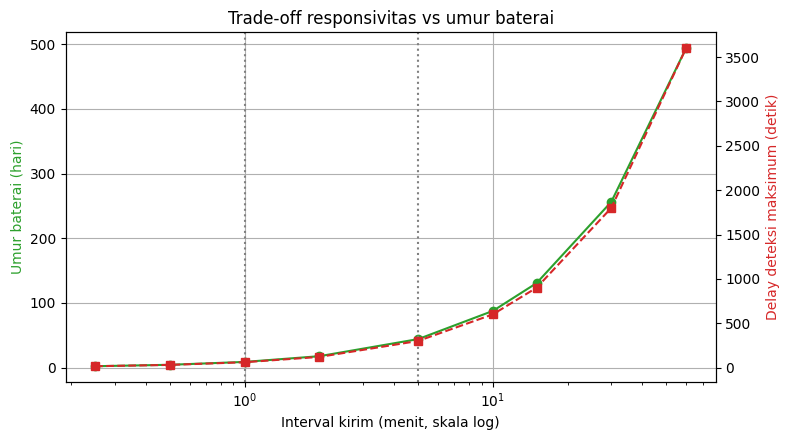

In [9]:
interval_menit = np.array([0.25, 0.5, 1, 2, 5, 10, 15, 30, 60])
umur_hari   = np.array([umur_baterai(m*60)[2] for m in interval_menit])
delay_maks  = interval_menit * 60            # detik, kondisi terburuk deteksi kejadian
delay_rata2 = delay_maks / 2

df = pd.DataFrame({"Interval (menit)": interval_menit,
                   "Umur (hari)": umur_hari.round(1),
                   "Delay deteksi rata-rata (detik)": delay_rata2,
                   "Delay deteksi maks (detik)": delay_maks}).set_index("Interval (menit)")
display(df)

fig, ax1 = plt.subplots()
ax1.semilogx(interval_menit, umur_hari, "o-", color="tab:green")
ax1.set_xlabel("Interval kirim (menit, skala log)"); ax1.set_ylabel("Umur baterai (hari)", color="tab:green")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.semilogx(interval_menit, delay_maks, "s--", color="tab:red")
ax2.set_ylabel("Delay deteksi maksimum (detik)", color="tab:red")
for m in (1, 5):
    ax1.axvline(m, color="gray", ls=":")
plt.title("Trade-off responsivitas vs umur baterai"); plt.tight_layout(); plt.show()

### 3.3 Strategi Mitigasi (opsional, kuantitatif)
Jika monitoring harus tetap sering, kita bisa menurunkan **energi per siklus**, misalnya dengan mempersingkat waktu aktif (koneksi WiFi cepat/static IP, atau ganti ke LoRa/BLE).

In [10]:
for t_aktif in (3.0, 1.5, 0.5):
    T_AKTIF_s = t_aktif
    _, _, h = umur_baterai(60)
    print(f"Interval 1 menit, waktu aktif {t_aktif:>3} s -> umur {h:5.1f} hari")
T_AKTIF_s = 3.0   # kembalikan

Interval 1 menit, waktu aktif 3.0 s -> umur   8.9 hari
Interval 1 menit, waktu aktif 1.5 s -> umur  17.7 hari
Interval 1 menit, waktu aktif 0.5 s -> umur  52.9 hari


### 3. Trade-off *Responsivitas Monitoring* vs *Umur Baterai*

**Hasil:** memperpendek interval dari 5 menit ke 1 menit membuat jumlah transmisi naik **5×** (288 → 1440 per hari). Karena energi didominasi fase aktif (bukan sleep), arus rata-rata naik hampir **5×** dan umur baterai turun dari ≈ **44 hari** menjadi ≈ **9 hari** (dengan asumsi di atas).

**Penjelasan trade-off:**
- **Responsivitas ↑:** delay deteksi maksimum turun dari 5 menit menjadi 1 menit (rata-rata 2,5 menit → 30 detik). Cocok untuk kondisi kritis (mis. alarm suhu cold-chain, kebocoran).
- **Umur baterai ↓:** biaya perawatan naik (penggantian/pengisian baterai 5× lebih sering), terutama untuk node di lokasi sulit dijangkau.
- **Hubungan non-linear:** umur ≈ berbanding terbalik dengan frekuensi kirim. Dari grafik, memperpanjang interval pada rentang pendek memberi tambahan umur yang besar; pada interval sangat panjang kurva mulai melandai karena arus sleep dan self-discharge mulai berperan.
- **Prinsip desain:** tentukan interval dari kebutuhan **latensi aplikasi**, bukan "semakin sering semakin baik".

**Rekomendasi mitigasi:**
1. **Event-driven / adaptive reporting:** kirim hanya jika perubahan melewati ambang (*report by exception*), plus heartbeat jarang (mis. 15 menit).
2. **Interval adaptif:** normal 5 menit, otomatis 1 menit hanya saat nilai mendekati batas bahaya.
3. **Batching:** ukur tiap 1 menit tetapi kirim sekali per 5 menit (sensor cukup membangunkan MCU sebentar, radio tetap hemat).
4. **Kurangi t_aktif:** koneksi cepat, payload kecil, atau radio hemat daya (LoRa/BLE/NB-IoT).
5. **Tambah kapasitas / energy harvesting** (panel surya kecil) bila interval 1 menit memang wajib.

## Ringkasan Seluruh Tugas

| Tugas | Temuan utama |
|---|---|
| 1. Edge-AI gateway | Bobot berbeda → rekomendasi berubah dari platform hemat daya (ESP32/STM32) ke platform berdaya komputasi tinggi (Jetson Nano / RPi). Keputusan sensitif terhadap bobot. |
| 2. ADC 16-bit | Resolusi naik 16×, tetapi error total hampir tak berubah karena noise & akurasi sensor mendominasi → 12-bit cukup untuk sensor suhu umum. |
| 3. Interval 1 menit | Umur baterai turun ≈5× (≈44 → ≈9 hari); trade-off nyata antara delay deteksi dan umur baterai, bisa dimitigasi dengan strategi adaptif/batching. |